<a href="https://colab.research.google.com/github/julia-zhmurko/JuliaZhmurko-ML/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D1%96_%D1%80%D0%BE%D0%B1%D0%BE%D1%82%D0%B8/%D0%96%D0%BC%D1%83%D1%80%D0%BA%D0%BE_%D0%AE%D0%BB%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_10_%D0%9B%D0%A0_8_%D0%9C%D0%9D_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

**Виконала:** студентка групи ФІТ 4-10 Жмурко Юлія Андріївна

**Була присутня на парі (18.11.2026)**

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [38]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

###**Пояснення:**

Виконаємо імпорт бібліотек та інструментів Python, необхідних для проведення кластеризації набору даних `Iris`, оцінювання якості кластеризації та візуалізації отриманих результатів.

- `matplotlib.pyplot (plt)` – використовується для побудови графіків та візуалізації результатів кластеризації.

- `pandas (pd)` – призначена для роботи з табличними даними, їх обробки та аналізу.

- `seaborn (sns)` – використовується для створення статистичних графіків та наочного представлення даних.

- `load_iris` – функція бібліотеки `sklearn.datasets`, яка завантажує вбудований набір даних `Iris`, що містить характеристики квітів ірису.

- `KMeans` – алгоритм кластеризації бібліотеки `sklearn.cluster`, який розподіляє об'єкти на задану кількість кластерів на основі їхньої подібності.

- `silhouette_score` – функція бібліотеки `sklearn.metrics`, яка обчислює коефіцієнт силуета для оцінювання якості кластеризації.

- `StandardScaler` – інструмент бібліотеки `sklearn.preprocessing`, який використовується для стандартизації числових ознак шляхом приведення їх до нульового середнього значення та одиничного стандартного відхилення.

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [39]:
iris = load_iris()

df_iris = pd.DataFrame(iris.data, columns = iris.feature_names)

display(df_iris.head())

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


###**Опис ознак набору даних load_iris:**

**sepal length (cm)** - Довжина чашолистка квітки

**sepal width (cm)** - Ширина чашолистка квітки

**petal length (cm)** - Довжина пелюстки квітки

**petal width (cm)** - Ширина пелюстки квітки

Набір даних містить три класи квітів ірису:

- Iris setosa (0) – ірис щетинистий, 50 зразків.
- Iris versicolor (1) – ірис різнокольоровий, 50 зразків.
- Iris virginica (2) – ірис віргінський, 50 зразків.

###**Пояснення:**

За допомогою функції `load_iris()` завантажено набір даних `Iris`, який містить 150 зразків квітів ірису трьох видів. Використовуючи `pd.DataFrame()`, створено таблицю `df_iris` із числовими значеннями ознак та відповідними назвами стовпців. Функція `display(df_iris.head())` забезпечує виведення перших п’яти рядків таблиці.

За результатами виведення перших п’яти записів встановлено, що довжина чашолистка змінюється від 4,6 до 5,1 см, ширина чашолистка – від 3,0 до 3,6 см, довжина пелюстки – від 1,4 до 1,5 см, а ширина пелюстки для всіх п’яти зразків становить 0,2 см.

**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

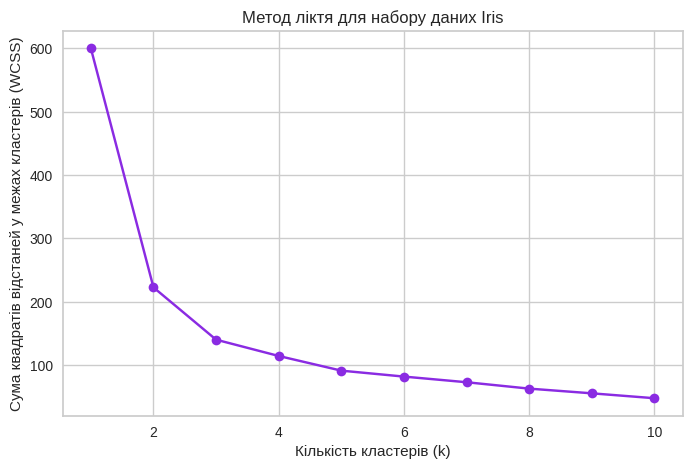

In [40]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_iris)

inertias = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters = k, init = 'k-means++', max_iter = 300, random_state = 42, n_init = 10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize = (8, 5))
plt.plot(range(1, 11), inertias, marker = 'o', color = 'blueviolet')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Сума квадратів відстаней у межах кластерів (WCSS)')
plt.title('Метод ліктя для набору даних Iris')
plt.grid(True)
plt.show()

###**Пояснення:**

За допомогою `StandardScaler()` виконано стандартизацію числових ознак набору даних `Iris`. Метод `fit_transform()` перетворює значення ознак таким чином, щоб їхнє середнє значення дорівнювало 0, а стандартне відхилення – 1. Це дозволяє забезпечити однаковий масштаб ознак та зменшити вплив відмінностей між діапазонами їхніх значень на результати кластеризації.

Для визначення оптимальної кількості кластерів застосовано метод ліктя (`Elbow Method`), який базується на аналізі внутрішньокластерної суми квадратів відстаней (`WCSS`).

У циклі `for` послідовно створюються та навчаються моделі `KMeans` для кількості кластерів від 1 до 10. Під час налаштування алгоритму використано такі параметри:

- `n_clusters = k` – визначає кількість кластерів, на які розподіляються дані;

- `init = 'k-means++'` – забезпечує ефективний вибір початкових центрів кластерів;

- `max_iter = 300` – встановлює максимальну кількість ітерацій алгоритму;

- `random_state = 42` – забезпечує відтворюваність отриманих результатів;

- `n_init = 10` – задає кількість незалежних запусків алгоритму з різними початковими центрами кластерів.

Метод `fit(X_scaled)` виконує кластеризацію стандартизованих даних, а атрибут `inertia_` повертає значення `WCSS` для кожної моделі. Отримані значення зберігаються у списку `inertias` та використовуються для побудови графіка залежності внутрішньокластерної суми квадратів від кількості кластерів.

Аналіз отриманого графіка методу ліктя показує, що зі збільшенням кількості кластерів значення `WCSS` поступово зменшується. Найбільш суттєве зниження спостерігається під час переходу від одного до двох кластерів – приблизно з 600 до 223. При збільшенні кількості кластерів до трьох значення `WCSS` зменшується приблизно до 140.

Починаючи з `k = 3`, темп зменшення `WCSS` стає значно повільнішим, а крива поступово вирівнюється. Подальше збільшення кількості кластерів забезпечує менш суттєве покращення компактності сформованих груп.

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

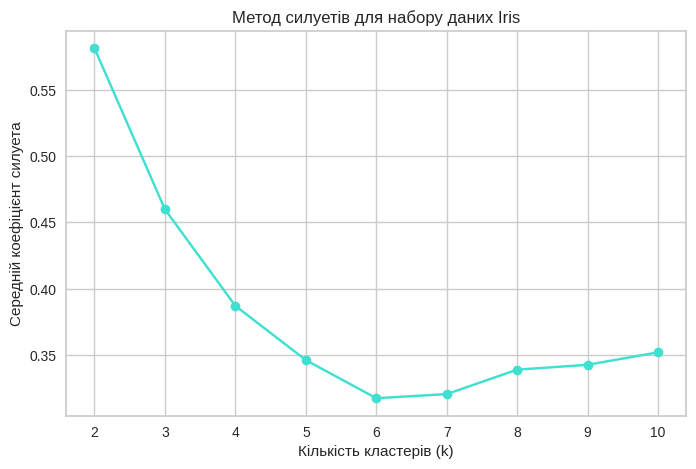

In [41]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters = k, init = 'k-means++', max_iter = 300, random_state = 42, n_init = 10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize = (8, 5))
plt.plot(range(2, 11), silhouette_scores, marker = 'o', color = 'turquoise')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів для набору даних Iris')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

###**Пояснення:**

Для додаткового визначення оптимальної кількості кластерів застосовано метод силуетів (`Silhouette Method`), який дозволяє оцінити якість кластеризації на основі компактності сформованих кластерів та ступеня їхньої відокремленості один від одного.

У циклі `for` послідовно створено моделі `KMeans` для кількості кластерів від 2 до 10 із використанням тих самих стандартизованих даних `X_scaled` та параметрів алгоритму, що й у методі ліктя.

Метод `fit_predict(X_scaled)` виконує кластеризацію даних і повертає мітки кластерів для кожного зразка. За допомогою функції `silhouette_score(X_scaled, labels)` обчислюється середній коефіцієнт силуета, який характеризує якість розподілу об'єктів між кластерами. Отримані значення зберігаються у списку `silhouette_scores` та використовуються для побудови графіка.

Коефіцієнт силуета набуває значень від −1 до 1. Значення, близькі до 1, свідчать про високу компактність та відокремленість кластерів, значення поблизу 0 вказують на можливе перекриття кластерів, а від'ємні значення можуть свідчити про некоректне віднесення окремих об'єктів до кластерів.

Аналіз отриманого графіка методу силуетів показує, що найбільше значення середнього коефіцієнта силуета спостерігається для `k = 2` і становить приблизно 0,582. Це свідчить про те, що розподіл набору даних `Iris` на два кластери забезпечує найкраще співвідношення компактності та відокремленості кластерів серед досліджених варіантів.

При збільшенні кількості кластерів до трьох середній коефіцієнт силуета зменшується приблизно до 0,460, а для чотирьох кластерів – до 0,387. Подальше збільшення кількості кластерів супроводжується поступовим зниженням показника, який досягає мінімального значення приблизно 0,316 при `k = 6`.

Для кількості кластерів від 7 до 10 спостерігається незначне зростання коефіцієнта силуета, проте його значення залишаються суттєво нижчими, ніж для двох і трьох кластерів.

Порівняння результатів методу ліктя та методу силуетів показує, що отримані рекомендації щодо оптимальної кількості кластерів відрізняються. Метод ліктя дозволив визначити доцільну кількість кластерів `k = 3`, тоді як за максимальним значенням середнього коефіцієнта силуета оптимальним є `k = 2`.

Така відмінність пояснюється тим, що метод ліктя оцінює зменшення внутрішньокластерної суми квадратів відстаней, а метод силуетів враховує одночасно компактність кластерів та їхню відокремленість. Крім того, набір даних `Iris` містить три відомі види квітів, два з яких мають частково схожі числові характеристики, що може ускладнювати їх розділення.

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

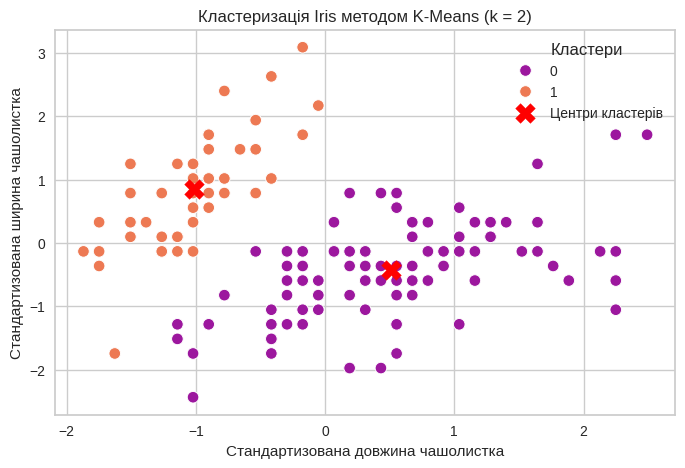

In [42]:
kmeans_final = KMeans(
    n_clusters = 2,
    init = 'k-means++',
    max_iter = 300,
    random_state = 42,
    n_init = 10
)

labels_final = kmeans_final.fit_predict(X_scaled)

centers = kmeans_final.cluster_centers_

plt.figure(figsize = (8, 5))

sns.scatterplot(
    x = X_scaled[:, 0],
    y = X_scaled[:, 1],
    hue = labels_final,
    palette = 'plasma',
    s = 70
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c = 'red',
    marker = 'X',
    s = 200,
    label = 'Центри кластерів'
)

plt.xlabel('Стандартизована довжина чашолистка')
plt.ylabel('Стандартизована ширина чашолистка')
plt.title('Кластеризація Iris методом K-Means (k = 2)')
plt.legend(title = 'Кластери')
plt.grid(True)
plt.show()

###**Пояснення:**

Для виконання фінальної кластеризації набору даних `Iris` створено модель `K-Means` із кількістю кластерів `k = 2`, що відповідає оптимальному значенню, визначеному за допомогою методу силуетів у попередньому пункті.

Модель `KMeans` налаштовано з використанням методу ініціалізації центрів `k-means++`, максимальної кількості ітерацій `max_iter = 300`, фіксованого значення `random_state = 42` та десяти незалежних запусків алгоритму (`n_init = 10`).

За допомогою методу `fit_predict(X_scaled)` виконано кластеризацію стандартизованих даних `Iris` за всіма чотирма числовими ознаками. Отримані мітки кластерів збережено у змінній `labels_final`, а координати центрів сформованих кластерів визначено за допомогою атрибута `cluster_centers_`.

Для візуалізації результатів використано функцію `sns.scatterplot()`, яка дозволяє відобразити об'єкти на двовимірній площині відповідно до їхньої належності до кластерів. На горизонтальній осі представлено стандартизовану довжину чашолистка, а на вертикальній – стандартизовану ширину чашолистка. Кольори точок визначаються мітками кластерів із використанням палітри `plasma`.

За допомогою функції `plt.scatter()` додатково відображено центри кластерів, які позначено червоними маркерами у формі літери `X`.

Аналіз отриманого графіка кластеризації показує, що алгоритм `K-Means` розподілив об'єкти набору даних `Iris` на два кластери, які відрізняються за своїми числовими характеристиками.

- Кластер 0 (фіолетовий колір) – містить переважно зразки з більшими значеннями стандартизованої довжини чашолистка. Об'єкти цього кластера розташовані переважно в центральній та правій частинах графіка, хоча окремі точки спостерігаються і в лівій частині.

- Кластер 1 (помаранчевий колір) – об'єднує переважно зразки з меншою довжиною та відносно більшою шириною чашолистка. Більшість об'єктів цього кластера зосереджена у верхній лівій частині графіка.

Центри сформованих кластерів розташовані приблизно в точках (0,5; −0,4) для кластера 0 та (−1,0; 0,9) для кластера 1. Їхнє положення відображає середні стандартизовані значення перших двох ознак для об'єктів відповідних кластерів.

На графіку спостерігається певне перекриття кластерів, зокрема в центральній та нижній лівій частинах площини. Це пояснюється тим, що кластеризація виконувалася за всіма чотирма числовими ознаками, тоді як для двовимірної візуалізації використано лише перші дві. Тому відображення на площині не повністю передає відмінності між об'єктами у чотиривимірному просторі ознак.

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

###**Висновок до завдання 1:**

За результатами кластеризації набору даних `Iris` із використанням алгоритму `K-Means` встановлено, що метод ліктя та метод силуетів дають дещо різні рекомендації щодо оптимальної кількості кластерів.

Метод ліктя показав, що найбільш суттєве зменшення внутрішньокластерної суми квадратів відстаней (`WCSS`) спостерігається при збільшенні кількості кластерів від 1 до 3. Після `k = 3` темп зменшення `WCSS` сповільнюється, тому три кластери можна вважати доцільним варіантом.

Метод силуетів показав, що найбільше значення середнього коефіцієнта силуета, приблизно 0,582, досягається при `k = 2`, тоді як для трьох кластерів цей показник становить приблизно 0,460. Це свідчить про кращу компактність та відокремленість двох кластерів порівняно з іншими перевіреними варіантами.

Для фінальної кластеризації обрано `k = 2`, оскільки саме ця кількість кластерів забезпечила найвище значення коефіцієнта силуета. Побудований графік підтвердив формування двох груп об'єктів із різними характеристиками, хоча на двовимірній площині спостерігається часткове перекриття кластерів.

Отже, вибір двох кластерів повністю узгоджується з результатами методу силуетів, але відрізняється від рекомендації методу ліктя (`k = 3`). Така відмінність пояснюється використанням різних критеріїв оцінювання якості кластеризації. Водночас отримані результати демонструють, що оптимальна кількість кластерів не обов'язково збігається з кількістю відомих класів у наборі даних.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [43]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

###**Пояснення:**

За допомогою операторів `import` та `from ... import` імпортовано бібліотеки й інструменти Python, необхідні для завантаження, попередньої обробки, аналізу даних студентів, побудови моделей класифікації та оцінювання їхньої якості.

- `pandas (pd)` – використовується для завантаження, обробки та аналізу табличних даних.

- `train_test_split` – функція бібліотеки `sklearn.model_selection`, яка забезпечує поділ набору даних на навчальну та тестову вибірки.

- `StandardScaler` – використовується для стандартизації числових ознак шляхом приведення їх до нульового середнього значення та одиничного стандартного відхилення.

- `matplotlib.pyplot (plt)` – призначена для побудови графіків та візуалізації результатів аналізу й класифікації.

- `seaborn (sns)` – використовується для створення статистичних графіків та наочного представлення залежностей між ознаками.

- `GridSearchCV` – інструмент бібліотеки `sklearn.model_selection`, який виконує пошук найкращих гіперпараметрів моделі за допомогою перехресної перевірки.

- `RandomForestClassifier` – алгоритм класифікації на основі ансамблю дерев рішень, який формує прогноз шляхом об'єднання результатів окремих дерев.

- `LogisticRegression` – модель логістичної регресії, яка використовується для прогнозування належності об'єктів до певних класів.

- `SVC` – класифікатор на основі методу опорних векторів (`Support Vector Classification`), який визначає межі розділення між класами.

- `accuracy_score` – функція бібліотеки `sklearn.metrics`, яка обчислює частку правильно класифікованих об'єктів.

- `classification_report` – функція, яка формує звіт із метриками якості класифікації, зокрема `precision`, `recall` та `F1-score`.

- `os` – стандартний модуль Python для роботи з операційною системою, шляхами та файлами.

- `google.colab.files` – модуль середовища Google Colab, який дозволяє завантажувати файли з комп'ютера до середовища виконання.

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [44]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


###**Пояснення:**

За допомогою бібліотеки `kagglehub` виконано завантаження набору даних `Students Performance Dataset` із платформи `Kaggle` для подальшого аналізу та побудови моделей машинного навчання.

Функція `kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")` забезпечує доступ до актуальної версії набору даних, а змінна `path` зберігає шлях до каталогу із завантаженими файлами. Команда `print()` виводить отриманий шлях для перевірки доступності даних.

**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [45]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


###**Опис ознак набору даних Students Performance Dataset:**

`Students Performance Dataset` – набір даних, який містить інформацію про академічну успішність 2392 студентів старшої школи, їхні демографічні характеристики, навчальні звички, підтримку з боку батьків та участь у позанавчальній діяльності.

Набір даних містить 15 стовпців, зокрема ідентифікатор студента, 13 характеристик та цільову змінну `GradeClass`.

**StudentID** – унікальний ідентифікатор студента (від 1001 до 3392).

**Age** – вік студента (від 15 до 18 років).

**Gender** – стать студента:
- 0 – чоловіча;
- 1 – жіноча.

**Ethnicity** – етнічна належність студента:
- 0 – європеоїдна група (Caucasian);
- 1 – афроамериканська;
- 2 – азійська;
- 3 – інша.

**ParentalEducation** – рівень освіти батьків:
- 0 – відсутня формальна освіта;
- 1 – середня освіта;
- 2 – незавершена вища освіта (навчання в коледжі);
- 3 – ступінь бакалавра;
- 4 – вищий рівень освіти.

**StudyTimeWeekly** – кількість годин, які студент витрачає на навчання протягом тижня (від 0 до 20 годин).

**Absences** – кількість пропущених занять протягом навчального року (від 0 до 30).

**Tutoring** – наявність додаткових занять із репетитором:
- 0 – ні;
- 1 – так.

**ParentalSupport** – рівень підтримки студента з боку батьків:
- 0 – відсутня;
- 1 – низький;
- 2 – помірний;
- 3 – високий;
- 4 – дуже високий.

**Extracurricular** – участь у позанавчальних заходах:
- 0 – ні;
- 1 – так.

**Sports** – участь у спортивних заходах:
- 0 – ні;
- 1 – так.

**Music** – участь у музичній діяльності:
- 0 – ні;
- 1 – так.

**Volunteering** – участь у волонтерській діяльності:
- 0 – ні;
- 1 – так.

**GPA (Grade Point Average)** – середній бал академічної успішності студента за шкалою від 0,0 до 4,0. Вищі значення відповідають кращій успішності.

**GradeClass** – цільова ознака, яка визначає категорію академічної успішності студента:
- 0 – оцінка A (відмінно), GPA ≥ 3,5;
- 1 – оцінка B (добре), 3,0 ≤ GPA < 3,5;
- 2 – оцінка C (задовільно), 2,5 ≤ GPA < 3,0;
- 3 – оцінка D (низька успішність), 2,0 ≤ GPA < 2,5;
- 4 – оцінка F (незадовільно), GPA < 2,0.

###**Пояснення:**

За допомогою функції `pd.read_csv()` виконано зчитування CSV-файлу `Student_performance_data _.csv` із каталогу, шлях до якого збережено у змінній `path`. Функція `os.path.join()` забезпечує формування повного шляху до файлу, а отримані дані зберігаються у вигляді таблиці DataFrame у змінній `df`.

Метод `df.head()` дозволяє вивести перші п’ять рядків таблиці для ознайомлення зі структурою набору даних та значеннями його характеристик.

Аналіз перших п’яти записів показує, що вік студентів становить від 15 до 18 років, тривалість самостійного навчання змінюється приблизно від 4,21 до 19,83 години на тиждень, а кількість пропущених занять – від 0 до 26. Значення середнього бала `GPA` знаходяться приблизно в межах від 0,11 до 3,04, тоді як цільова ознака `GradeClass` у представлених записах набуває значень від 1 до 4.

**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [46]:
print("Назви стовпців набору даних Students Performance Dataset:")
print(df.columns.tolist())

Назви стовпців набору даних Students Performance Dataset:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


###**Пояснення:**

За допомогою атрибута `df.columns` отримано назви всіх стовпців набору даних `Students Performance Dataset`. Метод `tolist()` перетворює отриманий об'єкт типу `Index` у звичайний список Python, а функція `print()` забезпечує виведення відповідного заголовка та переліку назв стовпців.

Серед отриманих стовпців `StudentID` є унікальним ідентифікатором студента, `Age`, `Gender` та `Ethnicity` описують демографічні характеристики, `StudyTimeWeekly`, `Absences` і `Tutoring` відображають особливості навчальної діяльності, а `GPA` характеризує середній бал академічної успішності.

Стовпець `GradeClass` визначає категорію академічної успішності студента та виступатиме цільовою ознакою під час побудови моделей класифікації.

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [47]:
print("Структура набору даних Students Performance Dataset:")
df.info()

Структура набору даних Students Performance Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int6

###**Пояснення:**

За допомогою методу `df.info()` отримано загальну інформацію про структуру набору даних `Students Performance Dataset`, зокрема кількість записів і стовпців, типи даних, кількість непорожніх значень та обсяг використаної оперативної пам’яті.

Аналіз типів даних показав, що всі 15 стовпців мають числовий формат:

- `int64` (12 стовпців) – цілочисельні значення, які використовуються для представлення ідентифікаторів студентів, віку, демографічних характеристик, рівня освіти батьків, кількості пропусків занять та інших категоріальних ознак.

- `float64` (3 стовпці) – дійсні числа, які використовуються для представлення тривалості навчання протягом тижня (`StudyTimeWeekly`), середнього бала успішності (`GPA`) та цільової ознаки (`GradeClass`).

Показник `Non-Null Count` для кожного з 15 стовпців становить 2392. Це свідчить про те, що всі записи містять непорожні значення, а пропущені дані в наборі відсутні.

Варто зазначити, що хоча всі стовпці представлені числовими типами, частина з них містить закодовані категоріальні характеристики. Зокрема, `Gender`, `Ethnicity`, `ParentalEducation` та `ParentalSupport` мають числові значення, які відповідають певним категоріям, а не неперервним величинам. Крім того, цільова ознака `GradeClass`, незважаючи на тип `float64`, визначає категорію академічної успішності студента та використовується для задачі багатокласової класифікації.

**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [48]:
print("Кількість пропущених значень у кожному стовпці:")
display(df.isnull().sum())

print("\nЗагальна кількість пропущених значень:", df.isnull().sum().sum())

Кількість пропущених значень у кожному стовпці:


,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0



Загальна кількість пропущених значень: 0


###**Пояснення:**

За допомогою методу `df.isnull()` виконано перевірку набору даних `Students Performance Dataset` на наявність пропущених значень. Метод визначає відсутні значення в таблиці, повертаючи `True` для пропущених даних та `False` для заповнених.

Використання `df.isnull().sum()` дозволяє підрахувати кількість пропущених значень окремо для кожного стовпця. Функція `display()` забезпечує відображення отриманих результатів у зручному табличному форматі. Додатково за допомогою `df.isnull().sum().sum()` обчислено загальну кількість пропущених значень у всьому наборі даних.

Аналіз отриманих результатів показав, що в усіх 15 стовпцях кількість пропущених значень дорівнює 0. Зокрема, відсутні пропуски в демографічних характеристиках студентів (`Age`, `Gender`, `Ethnicity`), показниках навчальної діяльності (`StudyTimeWeekly`, `Absences`, `Tutoring`), характеристиках позанавчальної активності (`Extracurricular`, `Sports`, `Music`, `Volunteering`), а також в ознаках академічної успішності (`GPA`, `GradeClass`).

Загальна кількість пропущених значень у наборі даних становить 0, що підтверджує повноту заповнення всіх 2392 записів. Отримані результати також узгоджуються з попередньою перевіркою структури таблиці за допомогою методу `df.info()`, який показав однакову кількість непорожніх значень для кожного стовпця.

**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [49]:
print("Кількість дублікатів у наборі даних:", df.duplicated().sum())

Кількість дублікатів у наборі даних: 0


###**Пояснення:**

За допомогою методу `df.duplicated()` виконано перевірку набору даних `Students Performance Dataset` на наявність дублікатів, тобто повністю однакових записів у таблиці. Метод повертає логічні значення `True` для повторних входжень однакових рядків та `False` для унікальних записів.

Використання методу `sum()` дозволяє підрахувати загальну кількість виявлених дублікатів, а функція `print()` забезпечує виведення отриманого результату з відповідним пояснювальним підписом.

Аналіз отриманого результату показав, що кількість дублікатів у наборі даних становить 0. Це свідчить про відсутність повністю однакових рядків серед 2392 записів. Отже, кожен запис є унікальним за сукупністю значень усіх 15 стовпців, включно з ідентифікатором студента `StudentID`.

Водночас наявність унікального ідентифікатора `StudentID` означає, що записи з однаковими характеристиками студентів, але різними ідентифікаторами не вважатимуться дублікатами під час такої перевірки.

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [50]:
print("Основні описові статистики набору даних Students Performance Dataset:")
display(df.describe())

Основні описові статистики набору даних Students Performance Dataset:


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


###**Пояснення:**

За допомогою методу `df.describe()` обчислено основні описові статистики набору даних `Students Performance Dataset`, зокрема кількість непорожніх значень (`count`), середнє арифметичне (`mean`), стандартне відхилення (`std`), мінімальне (`min`) та максимальне (`max`) значення, а також квартилі (25%, 50%, 75%). Функція `display()` забезпечує відображення отриманих результатів у зручному табличному форматі.

Аналіз отриманих статистичних показників показав, що набір даних містить 2392 записи, причому для всіх 15 стовпців кількість непорожніх значень становить 2392. Це підтверджує відсутність пропущених значень, встановлену на попередніх етапах дослідження.

Основні результати аналізу числових характеристик студентів:

- `Age` (вік студентів) – середній вік становить приблизно 16,47 року, стандартне відхилення – 1,12 року. Мінімальний вік становить 15 років, максимальний – 18 років, а медіана дорівнює 16 рокам.

- `StudyTimeWeekly` (тривалість навчання протягом тижня) – середня тривалість навчання становить приблизно 9,77 години, стандартне відхилення – 5,65 години. Значення змінюються від 0,001 до 19,98 години на тиждень, а медіана становить приблизно 9,71 години.

- `Absences` (кількість пропущених занять) – середня кількість пропусків становить приблизно 14,54, стандартне відхилення – 8,47. Мінімальна кількість пропусків дорівнює 0, максимальна – 29, а медіана становить 15.

- `GPA` (середній бал академічної успішності) – середнє значення становить приблизно 1,91, стандартне відхилення – 0,92. Мінімальний бал дорівнює 0, максимальний – 4, а медіана становить приблизно 1,89.

Аналіз квартилів показав, що 50% студентів мають тривалість навчання протягом тижня приблизно від 5,04 до 14,41 години, кількість пропущених занять – від 7 до 22, а середній бал `GPA` знаходиться в межах приблизно від 1,17 до 2,62. Це дозволяє оцінити центральні діапазони значень основних числових характеристик та їхню мінливість.

Для категоріальних і бінарних ознак також отримано статистичні показники. Зокрема, середнє значення `Tutoring` становить приблизно 0,301, `Extracurricular` – 0,383, `Sports` – 0,304, `Music` – 0,197, а `Volunteering` – 0,157. Оскільки ці ознаки закодовані значеннями 0 та 1, їхні середні значення відображають частку студентів, які беруть участь у відповідних видах діяльності або користуються додатковими заняттями.

Окрему увагу приділено цільовій ознаці `GradeClass`, середнє значення якої становить приблизно 2,98, стандартне відхилення – 1,23, а медіана дорівнює 4. Значення цієї ознаки змінюються від 0 до 4 та визначають категорії академічної успішності студентів. Оскільки `GradeClass` є категоріальною змінною, її середнє значення не слід інтерпретувати як безпосередній показник успішності, проте отримані статистики дозволяють попередньо оцінити розподіл закодованих класів.

Водночас необхідно враховувати, що для таких ознак, як `Gender`, `Ethnicity`, `ParentalEducation` та `ParentalSupport`, числові значення використовуються для позначення категорій або рівнів.

**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [51]:
X = df.drop(columns = ['StudentID', 'GradeClass'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state = 42,
    stratify = y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір матриці ознак:", X.shape)
print("Розмір цільової змінної:", y.shape)

print("\nРозмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

print("\nРозмір стандартизованої навчальної вибірки:", X_train_scaled.shape)
print("Розмір стандартизованої тестової вибірки:", X_test_scaled.shape)

Розмір матриці ознак: (2392, 13)
Розмір цільової змінної: (2392,)

Розмір навчальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)

Розмір стандартизованої навчальної вибірки: (1913, 13)
Розмір стандартизованої тестової вибірки: (479, 13)


###**Пояснення:**

За допомогою методу `df.drop()` сформовано матрицю ознак `X`, з якої виключено стовпці `StudentID` та `GradeClass`. Стовпець `StudentID` є службовим ідентифікатором студента та не містить змістовної інформації для прогнозування академічної успішності, тоді як `GradeClass` використовується як цільова змінна `y`, що визначає категорію успішності студента.

Для поділу даних застосовано функцію `train_test_split()`, яка розділяє набір даних на навчальну та тестову вибірки у співвідношенні 80/20. Параметр `test_size = 0.2` визначає частку тестових даних, `random_state = 42` забезпечує відтворюваність результатів, а `stratify = y` дозволяє зберегти приблизно однакові пропорції класів цільової змінної в обох вибірках.

Після поділу виконано стандартизацію ознак за допомогою `StandardScaler()`. Метод `fit_transform(X_train)` обчислює середні значення та стандартні відхилення ознак навчальної вибірки й перетворює їх таким чином, щоб середнє значення кожної ознаки наближалося до 0, а стандартне відхилення – до 1. Метод `transform(X_test)` застосовує параметри масштабування, отримані на навчальних даних, до тестової вибірки. Такий підхід дозволяє уникнути витоку інформації з тестових даних під час попередньої обробки.

Аналіз отриманих результатів показав, що початкова матриця ознак `X` має розмірність (2392, 13), тобто містить 2392 записи та 13 вхідних ознак. Цільова змінна `y` має розмірність (2392,) і містить відповідні категорії академічної успішності студентів.

У результаті поділу отримано:

- Навчальна вибірка `X_train` – 1913 записів із 13 ознаками, що становить приблизно 80% початкового набору даних.

- Тестова вибірка `X_test` – 479 записів із 13 ознаками, що становить приблизно 20% початкового набору даних.

- Стандартизована навчальна вибірка `X_train_scaled` – матриця розмірністю (1913, 13).

- Стандартизована тестова вибірка `X_test_scaled` – матриця розмірністю (479, 13).

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [52]:
rf = RandomForestClassifier(random_state = 42)

param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(
    estimator = rf,
    param_grid = param_grid_rf,
    cv = 5,
    scoring = 'accuracy',
    n_jobs = -1,
    verbose = 2
)

grid_rf.fit(X_train_scaled, y_train)

best_rf = grid_rf.best_estimator_

y_pred_rf = best_rf.predict(X_test_scaled)

test_accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Найкращі гіперпараметри Random Forest:")
print(grid_rf.best_params_)

print(f"\nСередня CV-точність: {grid_rf.best_score_ * 100:.2f}%")
print(f"Точність на тестовій вибірці: {test_accuracy_rf * 100:.2f}%")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Найкращі гіперпараметри Random Forest:
{'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Середня CV-точність: 92.11%
Точність на тестовій вибірці: 91.02%


###**Пояснення:**

За допомогою `RandomForestClassifier(random_state = 42)` створено модель випадкового лісу з фіксованим генератором випадкових чисел для забезпечення відтворюваності результатів.

Для пошуку оптимальної конфігурації моделі сформовано словник `param_grid_rf`, який містить такі гіперпараметри:

- `n_estimators` – кількість дерев у випадковому лісі (100, 200 або 300).

- `max_depth` – максимальна глибина дерев рішень (None, 10, 20 або 30).

- `min_samples_split` – мінімальна кількість зразків, необхідна для розділення внутрішнього вузла дерева (2, 5 або 10).

- `min_samples_leaf` – мінімальна кількість зразків у кінцевому вузлі дерева (1, 2 або 4).

Для автоматичного підбору гіперпараметрів застосовано `GridSearchCV` із п'ятикратною перехресною перевіркою (`cv = 5`). Як основний критерій оцінювання використано точність класифікації (`scoring = 'accuracy'`). Параметр `n_jobs = -1` забезпечує паралельне виконання обчислень із використанням усіх доступних процесорних ядер, а `verbose = 2` дозволяє відстежувати процес пошуку оптимальних параметрів.

У результаті було перевірено 108 комбінацій гіперпараметрів, для кожної з яких виконано п'ятикратну перехресну перевірку, тобто загалом здійснено 540 навчань моделей.

Метод `grid_rf.fit(X_train_scaled, y_train)` виконує підбір гіперпараметрів на навчальній вибірці. За допомогою атрибута `best_estimator_` отримано найкращу модель `Random Forest`, яка використовується для прогнозування категорій успішності студентів тестової вибірки методом `predict(X_test_scaled)`. Функція `accuracy_score()` обчислює частку правильно класифікованих записів.

Отримана конфігурація передбачає використання 200 дерев рішень із максимальною глибиною 10, мінімальною кількістю двох зразків для розділення вузла та одного зразка в кінцевому вузлі дерева.

Аналіз отриманих результатів показав, що середня точність моделі `Random Forest` за результатами п'ятикратної перехресної перевірки становить 92,11%, що свідчить про високу частку правильно класифікованих студентів на валідаційних частинах навчальної вибірки.

На тестовій вибірці модель досягла точності 91,02%, тобто правильно визначила категорії академічної успішності приблизно для 91% студентів, дані яких не використовувалися під час навчання та підбору гіперпараметрів.

Різниця між середньою CV-точністю та тестовою точністю становить лише 1,09 відсотка, що вказує на відносно стабільну якість моделі на навчальних і тестових даних. Незначне зниження точності на тестовій вибірці не свідчить про виражене перенавчання, хоча для остаточної оцінки здатності моделі до узагальнення необхідно враховувати й інші метрики класифікації.

### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [53]:
lr = LogisticRegression(
    max_iter = 1000,
    random_state = 42
)

param_grid_lr = {
    'penalty': ['l1', 'l2'],
    'C': [0.01, 0.1, 1, 10, 100],
    'solver' : ['saga']
}

grid_lr = GridSearchCV(
    estimator = lr,
    param_grid = param_grid_lr,
    cv = 5,
    n_jobs = -1,
    verbose = 2
)

grid_lr.fit(X_train_scaled, y_train)

best_lr = grid_lr.best_estimator_

y_pred_lr = best_lr.predict(X_test_scaled)

test_accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Найкращі гіперпараметри Logistic Regression:")
print(grid_lr.best_params_)

print(f"\nСередня CV-точність: {grid_lr.best_score_ * 100:.2f}%")
print(f"Точність на тестовій вибірці: {test_accuracy_lr * 100:.2f}%")

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Найкращі гіперпараметри Logistic Regression:
{'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}

Середня CV-точність: 80.24%
Точність на тестовій вибірці: 81.84%


###**Пояснення:**

За допомогою `LogisticRegression()` створено модель логістичної регресії з максимальною кількістю ітерацій `max_iter = 1000` та фіксованим значенням `random_state = 42` для забезпечення відтворюваності результатів.

Для пошуку оптимальної конфігурації моделі сформовано словник `param_grid_lr`, який містить такі гіперпараметри:

- `penalty` – тип регуляризації (`l1` або `l2`), який використовується для обмеження складності моделі та зменшення ризику перенавчання.

- `C` – параметр, обернений до сили регуляризації, для якого перевірено значення 0,01; 0,1; 1; 10 та 100. Менші значення відповідають сильнішій регуляризації, а більші – слабшій.

- `solver` – алгоритм оптимізації параметрів моделі. Використано `saga`, який підтримує багатокласову класифікацію та регуляризацію типів `L1` і `L2`.
Для автоматичного підбору гіперпараметрів застосовано `GridSearchCV` із п'ятикратною перехресною перевіркою (`cv = 5`). Параметр `n_jobs = -1` забезпечує паралельне виконання обчислень, а `verbose = 2` дозволяє відстежувати процес пошуку оптимальних параметрів. Оскільки критерій `scoring` не задано явно, для моделі `Logistic Regression` використовується її стандартна метрика оцінювання – точність класифікації (`Accuracy`).

У результаті було перевірено 10 комбінацій гіперпараметрів, для кожної з яких виконано п'ятикратну перехресну перевірку, тобто загалом здійснено 50 навчань моделей.

Метод `grid_lr.fit(X_train_scaled, y_train)` виконує підбір оптимальних гіперпараметрів на стандартизованій навчальній вибірці. За допомогою атрибута `best_estimator_` отримано найкращу модель логістичної регресії, яку використано для прогнозування категорій академічної успішності студентів тестової вибірки методом `predict(X_test_scaled)`. Функція `accuracy_score()` дозволяє обчислити частку правильно класифікованих записів.

Отримана конфігурація передбачає використання `L1`-регуляризації з параметром `C = 0,1`, що забезпечує відносно сильне обмеження величини коефіцієнтів моделі та сприяє зануленню менш значущих коефіцієнтів.

Аналіз отриманих результатів показав, що середня точність моделі `Logistic Regression` за результатами п'ятикратної перехресної перевірки становить 80,24%, що свідчить про здатність моделі правильно визначати категорії академічної успішності для більшості студентів на валідаційних частинах навчальної вибірки.

На тестовій вибірці модель досягла точності 81,84%, тобто правильно класифікувала приблизно 82% студентів, дані яких не використовувалися під час навчання та підбору гіперпараметрів.

Різниця між тестовою та середньою `CV`-точністю становить 1,60 відсотка, причому тестова точність виявилася дещо вищою. Це свідчить про відносно стабільні результати моделі на різних вибірках та не вказує на очевидні ознаки перенавчання за цими показниками.

Порівняння з результатами моделі `Random Forest` показує, що логістична регресія продемонструвала нижчу точність класифікації. Для `Random Forest` середня `CV`-точність становила 92,11%, а тестова точність – 91,02%, тоді як для `Logistic Regression` ці показники дорівнюють 80,24% та 81,84% відповідно.

Отже, `Random Forest` перевищує `Logistic Regression` за середньою `CV`-точністю на 11,87 відсотка, а за точністю на тестовій вибірці – на 9,18 відсотка. Така відмінність може пояснюватися тим, що логістична регресія формує лінійні межі між класами, тоді як `Random Forest` здатний враховувати складніші нелінійні залежності та взаємодії між характеристиками студентів.

### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [54]:
svm = SVC(random_state = 42)

param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'linear']
}

grid_svm = GridSearchCV(
    estimator = svm,
    param_grid = param_grid_svm,
    cv = 5,
    n_jobs = -1,
    verbose = 2
)

grid_svm.fit(X_train_scaled, y_train)

best_svm = grid_svm.best_estimator_

y_pred_svm = best_svm.predict(X_test_scaled)

test_accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("Найкращі гіперпараметри SVM:")
print(grid_svm.best_params_)

print(f"\nСередня CV-точність: {grid_svm.best_score_ * 100:.2f}%")
print(f"Точність на тестовій вибірці: {test_accuracy_svm * 100:.2f}%")

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Найкращі гіперпараметри SVM:
{'C': 100, 'gamma': 1, 'kernel': 'linear'}

Середня CV-точність: 85.47%
Точність на тестовій вибірці: 84.97%


###**Пояснення:**

За допомогою `SVC(random_state = 42)` створено модель методу опорних векторів із фіксованим генератором випадкових чисел для забезпечення відтворюваності результатів.

Для пошуку оптимальної конфігурації моделі сформовано словник `param_grid_svm`, який містить такі гіперпараметри:

- `C` – параметр регуляризації, який визначає співвідношення між шириною розділювального відступу та штрафом за помилки класифікації. Перевірено значення 0,1; 1; 10 та 100.

- `gamma` – параметр, який визначає ступінь впливу окремих навчальних зразків під час використання ядра `RBF`. Перевірено значення 1; 0,1; 0,01 та 0,001.

- `kernel` – тип ядра, який визначає спосіб побудови меж між класами. Використано `rbf` (радіальне базисне ядро) та `linear` (лінійне ядро).

Для автоматичного підбору гіперпараметрів застосовано `GridSearchCV` із п'ятикратною перехресною перевіркою (`cv = 5`). Параметр `n_jobs` = -1 забезпечує паралельне виконання обчислень, а `verbose = 2` дозволяє відстежувати процес пошуку оптимальних параметрів. Оскільки критерій `scoring` не задано явно, для моделі `SVC` використовується стандартна метрика оцінювання – точність класифікації (`Accuracy`).

У результаті було перевірено 32 комбінації гіперпараметрів, для кожної з яких виконано п'ятикратну перехресну перевірку, тобто загалом здійснено 160 навчань моделей.

Метод `grid_svm.fit(X_train_scaled, y_train)` виконує пошук оптимальних гіперпараметрів на стандартизованій навчальній вибірці. За допомогою атрибута `best_estimator_` отримано найкращу модель `SVM`, яку використано для прогнозування категорій академічної успішності студентів тестової вибірки методом `predict(X_test_scaled)`. Функція `accuracy_score()` дозволяє обчислити частку правильно класифікованих записів.

Отримана конфігурація передбачає використання лінійного ядра `linear` з параметром регуляризації `C = 100`. Велике значення параметра `C` означає слабшу регуляризацію та більший штраф за помилки класифікації, що дозволяє моделі точніше підлаштовувати розділювальні межі до навчальних даних.

Аналіз отриманих результатів показав, що середня точність моделі `SVM` за результатами п'ятикратної перехресної перевірки становить 85,47%, що свідчить про здатність моделі правильно визначати категорії академічної успішності для більшості студентів на валідаційних частинах навчальної вибірки.

На тестовій вибірці модель досягла точності 84,97%, тобто правильно класифікувала приблизно 85% студентів, дані яких не використовувалися під час навчання та підбору гіперпараметрів.

Різниця між середньою `CV`-точністю та тестовою точністю становить лише 0,50 відсотка, що свідчить про відносно стабільні результати моделі на різних вибірках та не вказує на очевидні ознаки перенавчання за цими показниками.

Порівняння з попередніми моделями `Random Forest` та `Logistic Regression` показує, що `SVM` продемонстрував проміжні результати за точністю класифікації.

Модель `SVM` перевищила `Logistic Regression` за середньою `CV`-точністю на 5,23 відсотка, а за точністю на тестовій вибірці – на 3,13 відсотка. Водночас порівняно з `Random Forest` точність `SVM` виявилася нижчою на 6,64 відсотка за результатами перехресної перевірки та на 6,05 відсотка на тестовій вибірці.

Отримані відмінності свідчать про те, що метод опорних векторів із лінійним ядром краще впорався із задачею класифікації, ніж логістична регресія, проте поступився алгоритму випадкового лісу. Це може пояснюватися здатністю `Random Forest` ефективніше враховувати складні нелінійні залежності та взаємодії між характеристиками студентів.

Водночас показник `Accuracy` відображає загальну частку правильних прогнозів і не дозволяє окремо оцінити якість класифікації кожної категорії `GradeClass`. Для повнішого аналізу результатів доцільно додатково використовувати метрики `Precision`, `Recall` та `F1-score`.

### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [55]:
results = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV-точність (%)': [
        grid_rf.best_score_ * 100,
        grid_lr.best_score_ * 100,
        grid_svm.best_score_ * 100
    ],
    'Тестова точність (%)': [
        test_accuracy_rf * 100,
        test_accuracy_lr * 100,
        test_accuracy_svm * 100
    ]
})

print("Порівняння результатів моделей класифікації:")
display(results.round(2))

best_model_name = results.loc[results['CV-точність (%)'].idxmax(), 'Модель']

best_models = {
    'Random Forest': best_rf,
    'Logistic Regression': best_lr,
    'SVM': best_svm
}

best_model = best_models[best_model_name]

print(f"\nНайкраща модель за CV-точністю: {best_model_name}")

y_pred_best = best_model.predict(X_test_scaled)

print("\nЗвіт класифікації найкращої моделі:")
print(classification_report(y_test, y_pred_best, zero_division = 0))

Порівняння результатів моделей класифікації:


,Модель,CV-точність (%),Тестова точність (%)
0,Random Forest,92.11,91.02
1,Logistic Regression,80.24,81.84
2,SVM,85.47,84.97



Найкраща модель за CV-точністю: Random Forest

Звіт класифікації найкращої моделі:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



###**Пояснення:**

Для порівняння ефективності трьох моделей класифікації `Random Forest`, `Logistic Regression` та `Support Vector Machine (SVM)` сформовано таблицю `results` за допомогою `pd.DataFrame()`, яка містить середню точність перехресної перевірки (`CV Accuracy`) та точність на тестовій вибірці (`Test Accuracy`) для кожного алгоритму.

Значення `CV`-точності отримано за допомогою атрибута `best_score_` відповідних об'єктів `GridSearchCV`, а тестову точність – із раніше обчислених змінних `test_accuracy_rf`, `test_accuracy_lr` та `test_accuracy_svm`. Усі показники представлено у відсотках, а метод `round(2)` використано для округлення значень до двох знаків після коми.

Для автоматичного визначення найкращої моделі застосовано метод `idxmax()`, який знаходить індекс рядка з найбільшим значенням `CV`-точності. За допомогою `loc[]` отримано назву відповідної моделі, після чого зі словника `best_models` вибрано її навчений екземпляр.

Метод `predict(X_test_scaled)` використано для прогнозування категорій академічної успішності студентів тестової вибірки. Для детального оцінювання якості найкращої моделі застосовано функцію `classification_report()`, яка обчислює показники `Precision`, `Recall`, `F1-score` та `Support` для кожного класу.

Аналіз отриманих результатів показав, що найвищу точність класифікації продемонструвала модель `Random Forest`, яка досягла середньої `CV`-точності 92,11% та тестової точності 91,02%. Це свідчить про її здатність ефективно прогнозувати категорії академічної успішності студентів на основі досліджуваних характеристик.

Друге місце посіла модель `Support Vector Machine`, яка забезпечила середню `CV`-точність 85,47% та тестову точність 84,97%. Найнижчі показники отримано для `Logistic Regression`, середня `CV`-точність якої становить 80,24%, а тестова точність – 81,84%.

Порівняння тестових результатів показує, що `Random Forest` перевищує `SVM` за точністю на 6,05 відсотка, а `Logistic Regression` – на 9,18 відсотка. Отримані відмінності можуть пояснюватися здатністю випадкового лісу враховувати складні нелінійні залежності та взаємодії між характеристиками студентів.

Оскільки `Random Forest` продемонстрував найвище значення середньої `CV`-точності, саме цю модель обрано для формування підсумкового звіту класифікації.

Аналіз показників якості класифікації за окремими класами показав:

- **Клас 0 (A)** – значення `Precision` становить 1,00, тобто всі об'єкти, які модель віднесла до цього класу, були класифіковані правильно. Водночас `Recall` дорівнює лише 0,29, а `F1-score` – 0,44, що свідчить про низьку здатність моделі виявляти всіх студентів із найвищою академічною успішністю.

- **Клас 1 (B)** – значення `Precision` становить 0,82, `Recall` – 0,85, а `F1-score` – 0,84. Це свідчить про достатньо збалансовану якість класифікації студентів цієї категорії.

- **Клас 2 (C)** – отримано `Precision` 0,89, `Recall` 0,95 та `F1-score` 0,92, що вказує на високу ефективність моделі у визначенні студентів із відповідним рівнем успішності.

- **Клас 3 (D)** – значення `Precision`, `Recall` та `F1-score` становлять 0,89, що свідчить про відносно збалансовану якість класифікації цієї категорії.

- **Клас 4 (F)** – отримано найвище значення `F1-score`, яке становить 0,96, при `Precision` 0,94 та `Recall` 0,97. Це свідчить про високу ефективність моделі у визначенні студентів із найнижчою академічною успішністю.

Додатковий аналіз узагальнених метрик показав, що загальна точність класифікації (`Accuracy`) становить приблизно 0,91, тобто 91% записів тестової вибірки класифіковано правильно.

Значення `Macro Average` становлять 0,91 для `Precision`, 0,79 для `Recall` та 0,81 для `F1-score`. Нижчі показники `Macro Recall` і `Macro F1-score` порівняно із загальною точністю свідчать про нерівномірну якість класифікації різних категорій студентів, зокрема через низьку повноту для класу 0.

Водночас `Weighted Average` становить 0,91 для `Precision`, 0,91 для `Recall` та 0,90 для `F1-score`. Ці показники враховують чисельність кожного класу та демонструють загалом високу якість прогнозування на тестовій вибірці.

Аналіз значень `Support` показав, що розподіл класів є нерівномірним. Найбільшу кількість записів має клас 4 (243 студенти), тоді як найменшу – клас 0 (21 студент). Така незбалансованість може впливати на якість класифікації окремих категорій, оскільки модель має значно більше навчальних прикладів для поширених класів.

Отже, незважаючи на високу загальну точність `Random Forest`, модель значно краще розпізнає студентів класу 4, ніж класу 0. Це підкреслює важливість використання не лише `Accuracy`, а й додаткових метрик для оцінювання якості багатокласової класифікації.

### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

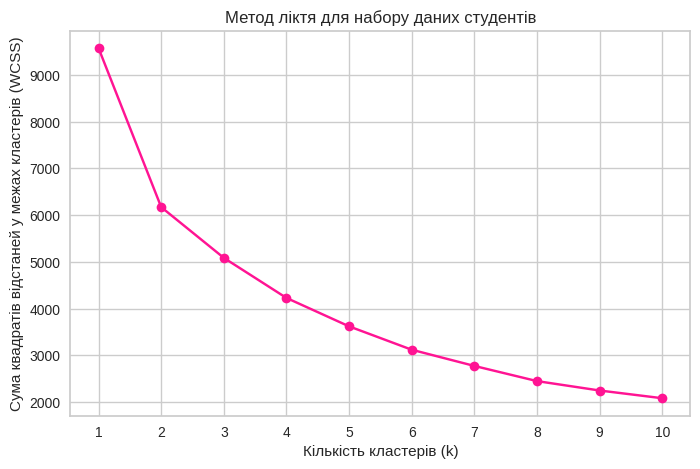

In [56]:
features_cluster = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_cluster = df[features_cluster]

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

inertias_students = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters = k,
        init = 'k-means++',
        max_iter = 300,
        random_state = 42,
        n_init = 10
    )
    kmeans.fit(X_cluster_scaled)
    inertias_students.append(kmeans.inertia_)

plt.figure(figsize = (8, 5))
plt.plot(range(1, 11), inertias_students, marker = 'o', color = 'deeppink')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Сума квадратів відстаней у межах кластерів (WCSS)')
plt.title('Метод ліктя для набору даних студентів')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

###**Пояснення:**

Для дослідження можливості групування студентів набору даних `Students Performance Dataset` за подібністю їхніх характеристик застосовано алгоритм `K-Means` та метод ліктя (`Elbow Method`), який дозволяє попередньо визначити оптимальну кількість кластерів на основі аналізу внутрішньокластерної суми квадратів відстаней (`WCSS`).

Для кластеризації вибрано чотири числові ознаки: `Age` (вік студента), `StudyTimeWeekly` (кількість годин навчання протягом тижня), `Absences` (кількість пропущених занять) та `GPA` (середній бал академічної успішності). За допомогою `df[features_cluster]` сформовано матрицю `X_cluster`, яка містить лише зазначені характеристики студентів без використання цільової змінної `GradeClass`.

Для приведення ознак до єдиного масштабу застосовано `StandardScaler()`. Метод `fit_transform(X_cluster)` виконує стандартизацію значень кожної ознаки таким чином, щоб їхнє середнє значення наближалося до 0, а стандартне відхилення – до 1. Це дозволяє зменшити вплив відмінностей між діапазонами значень ознак на результати кластеризації.

Для визначення оптимальної кількості кластерів використано метод ліктя, у межах якого послідовно створено та навчено моделі `KMeans` для кількості кластерів від 1 до 10. Під час налаштування алгоритму використано такі параметри:

- `n_clusters = k` – кількість кластерів, на які розподіляються студенти;

- `init = 'k-means++'` – спосіб вибору початкових центрів кластерів;

- `max_iter = 300` – максимальна кількість ітерацій алгоритму;

- `random_state = 42` – забезпечує відтворюваність результатів;

- `n_init = 10` – визначає кількість незалежних запусків алгоритму з різними початковими центрами кластерів.

Метод `fit(X_cluster_scaled)` виконує кластеризацію стандартизованих даних, а атрибут `inertia_` повертає значення внутрішньокластерної суми квадратів відстаней (`WCSS`) для кожної моделі. Отримані значення зберігаються у списку `inertias_students` та використовуються для побудови графіка залежності `WCSS` від кількості кластерів.

Аналіз отриманого графіка методу ліктя показує, що зі збільшенням кількості кластерів значення `WCSS` поступово зменшується. Найбільш суттєве зниження спостерігається під час переходу від одного до двох кластерів – приблизно з 9570 до 6200, що свідчить про значне покращення компактності сформованих груп.

При збільшенні кількості кластерів до трьох значення `WCSS` зменшується приблизно до 5100, а для чотирьох кластерів – до 4240. Подальше збільшення кількості кластерів супроводжується поступовим зниженням показника, проте темп цього зменшення стає менш вираженим.

Для п'яти кластерів значення `WCSS` становить приблизно 3640, для шести – 3120, а при збільшенні кількості кластерів до десяти зменшується приблизно до 2100.

На відміну від графіка методу ліктя для набору даних `Iris`, отримана крива для студентів не має чітко вираженого різкого вигину. Найбільше зменшення `WCSS` спостерігається при переході від одного до двох кластерів, після чого крива поступово вирівнюється. Водночас помітне зниження значень `WCSS` продовжується приблизно до `k = 4`, тому це значення можна розглядати як один із можливих варіантів для подальшого дослідження.

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

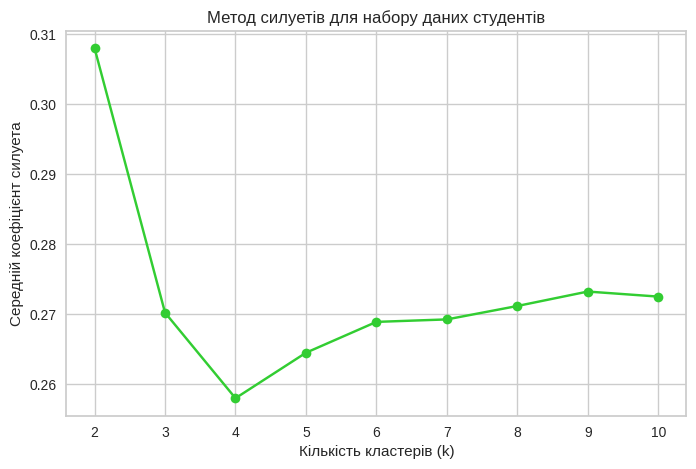

In [57]:
silhouette_scores_students = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters = k,
        init = 'k-means++',
        max_iter = 300,
        random_state = 42,
        n_init = 10
    )

    labels = kmeans.fit_predict(X_cluster_scaled)
    score = silhouette_score(X_cluster_scaled, labels)
    silhouette_scores_students.append(score)

plt.figure(figsize = (8, 5))
plt.plot(range(2, 11), silhouette_scores_students, marker = 'o', color = 'limegreen')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів для набору даних студентів')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

###**Пояснення:**

Для дослідження використано ті самі чотири стандартизовані числові ознаки, що й у попередньому пункті: `Age` (вік студента), `StudyTimeWeekly` (кількість годин навчання протягом тижня), `Absences` (кількість пропущених занять) та `GPA` (середній бал академічної успішності).

У циклі `for` послідовно створено моделі `KMeans` для кількості кластерів від 2 до 10. Під час налаштування алгоритму використано метод ініціалізації центрів `k-means++`, максимальну кількість ітерацій `max_iter = 300`, фіксоване значення `random_state = 42` та десять незалежних запусків алгоритму (`n_init = 10`).

Метод `fit_predict(X_cluster_scaled)` виконує кластеризацію стандартизованих даних студентів та повертає мітки кластерів для кожного запису. За допомогою функції `silhouette_score(X_cluster_scaled, labels)` обчислюється середній коефіцієнт силуета, який характеризує якість розподілу об'єктів між кластерами. Отримані значення зберігаються у списку `silhouette_scores_students` та використовуються для побудови графіка.

Коефіцієнт силуета набуває значень від −1 до 1. Значення, близькі до 1, свідчать про високу компактність та відокремленість кластерів, значення поблизу 0 вказують на можливе перекриття кластерів, а від'ємні значення можуть свідчити про некоректне віднесення окремих об'єктів до кластерів.

Аналіз отриманого графіка методу силуетів показує, що найбільше значення середнього коефіцієнта силуета спостерігається для `k = 2` і становить приблизно 0,308. Це свідчить про те, що розподіл студентів на два кластери забезпечує найкраще співвідношення компактності та відокремленості серед досліджених варіантів.

При збільшенні кількості кластерів до трьох середній коефіцієнт силуета зменшується приблизно до 0,270, а для чотирьох кластерів досягає мінімального значення – приблизно 0,258. Це вказує на погіршення якості розділення об'єктів за відповідних конфігурацій кластеризації.

Починаючи з `k = 5`, спостерігається поступове зростання коефіцієнта силуета: для п'яти кластерів його значення становить приблизно 0,264, для шести – 0,269, а для восьми – 0,271. Найвище значення серед варіантів із кількістю кластерів понад два досягається при `k = 9` і становить приблизно 0,273, після чого для десяти кластерів показник незначно зменшується до 0,272.

Водночас усі отримані значення коефіцієнта силуета є відносно низькими та не перевищують 0,31. Це свідчить про те, що сформовані кластери недостатньо чітко відокремлені один від одного, а частина студентів може мати схожі характеристики незалежно від належності до певної групи.

Порівняння результатів методу ліктя та методу силуетів показує, що метод ліктя не дозволив однозначно визначити оптимальну кількість кластерів, хоча значення `k = 4` розглядалося як один із можливих варіантів. Натомість метод силуетів продемонстрував чіткий максимум при `k = 2`, що дозволяє обґрунтувати вибір двох кластерів для подальшого дослідження.

Відмінність між результатами пояснюється тим, що метод ліктя оцінює зменшення внутрішньокластерної суми квадратів відстаней (`WCSS`), тоді як метод силуетів одночасно враховує компактність кластерів та їхню відокремленість. Тому максимальне значення коефіцієнта силуета є додатковим аргументом на користь вибору `k = 2`.

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [58]:
!pip install kneed yellowbrick

###**Пояснення:**

За допомогою команди `!pip install kneed yellowbrick` виконано встановлення додаткових пакетів Python, необхідних для автоматичного визначення оптимальної кількості кластерів та візуального аналізу результатів кластеризації.

Пакет `kneed` призначений для автоматичного пошуку характерних точок вигину на кривих, зокрема точки ліктя на графіку залежності внутрішньокластерної суми квадратів відстаней (`WCSS`) від кількості кластерів. Пакет `yellowbrick` містить інструменти для візуалізації та оцінювання моделей машинного навчання, зокрема алгоритмів кластеризації.

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [59]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

print("Бібліотеки PCA, KneeLocator та NumPy успішно імпортовано.")

Бібліотеки PCA, KneeLocator та NumPy успішно імпортовано.


###**Пояснення:**

За допомогою операторів `from ... import` та `import` виконано імпорт бібліотек та інструментів Python, необхідних для зменшення розмірності набору даних студентів і автоматичного визначення оптимальної кількості кластерів.

- `PCA` – клас бібліотеки `sklearn.decomposition`, який реалізує метод головних компонент (`Principal Component Analysis`). Використовується для зменшення розмірності даних шляхом перетворення початкових ознак на нові головні компоненти, які зберігають найбільшу можливу частку дисперсії.

- `KneeLocator` – клас бібліотеки `kneed`, який використовується для автоматичного визначення точки характерного вигину кривої. У задачі кластеризації дозволяє знайти точку ліктя на графіку `WCSS` та оцінити доцільну кількість кластерів.

- `numpy (np)` – бібліотека для виконання числових обчислень, роботи з багатовимірними масивами та математичними операціями.

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [60]:
X_pca = df.drop(columns = ['StudentID', 'GradeClass'])

print("Розмір матриці ознак для PCA:", X_pca.shape)
print("Кількість ознак для PCA:", X_pca.shape[1])

Розмір матриці ознак для PCA: (2392, 13)
Кількість ознак для PCA: 13


###**Пояснення:**

За допомогою методу `df.drop()` виконано формування матриці вхідних ознак `X_pca` набору даних `Students Performance Dataset`, з якої виключено стовпці `StudentID` та `GradeClass`.

Стовпець `StudentID` є службовим ідентифікатором студента та не містить змістовної інформації для дослідження подібності об'єктів, тоді як `GradeClass` визначає категорію академічної успішності та використовується як цільова змінна в задачі класифікації. Оскільки подальше дослідження передбачає застосування методу головних компонент (`PCA`) та кластеризацію без використання відомих міток класів, зазначені стовпці виключено з аналізу.

Для перевірки структури сформованої матриці використано атрибут `shape`, який повертає її розмірність у вигляді кількості рядків і стовпців. Вираз `X_pca.shape[1]` дозволяє окремо визначити кількість вхідних ознак.

Аналіз отриманих результатів показав, що сформована матриця `X_pca` має розмірність (2392, 13), тобто містить 2392 записи студентів та 13 вхідних ознак. Це підтверджує, що з початкових 15 стовпців успішно виключено службовий ідентифікатор і цільову змінну, залишивши характеристики, необхідні для подальшого аналізу.

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [61]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca)

pca = PCA(random_state = 42)
X_pca_transformed = pca.fit_transform(X_pca_scaled)

explained_variance = pca.explained_variance_ratio_

print("Частка поясненої дисперсії кожної головної компоненти:\n")
for i, variance in enumerate(explained_variance, start = 1):
    print(f"PC{i}: {variance * 100:.2f}%")

print(f"\nЗагальна пояснена дисперсія: {explained_variance.sum() * 100:.2f}%")

Частка поясненої дисперсії кожної головної компоненти:

PC1: 15.25%
PC2: 8.61%
PC3: 8.27%
PC4: 8.07%
PC5: 7.86%
PC6: 7.79%
PC7: 7.63%
PC8: 7.60%
PC9: 7.44%
PC10: 7.38%
PC11: 7.17%
PC12: 6.75%
PC13: 0.18%

Загальна пояснена дисперсія: 100.00%


###**Пояснення:**

Для дослідження структури багатовимірних даних студентів застосовано метод головних компонент (`Principal Component Analysis, PCA`), який дозволяє перетворити початкові ознаки на нові компоненти, впорядковані за часткою поясненої дисперсії.

Спочатку за допомогою `StandardScaler()` виконано стандартизацію всіх 13 вхідних ознак. Метод `fit_transform(X_pca)` перетворює їхні значення таким чином, щоб середнє значення кожної ознаки наближалося до 0, а стандартне відхилення – до 1. Це забезпечує порівнянність характеристик, які мають різні масштаби та діапазони значень.

Після стандартизації створено модель `PCA(random_state = 42)`. Метод `fit_transform(X_pca_scaled)` виконує перетворення стандартизованих даних у простір головних компонент. Оскільки параметр `n_components` не задано, модель зберігає всі 13 головних компонент.

Для визначення частки дисперсії, яку пояснює кожна компонента, використано атрибут `explained_variance_ratio_`. Отримані значення збережено у змінній `explained_variance` та виведено у відсотках за допомогою циклу `for`.

Аналіз отриманих результатів показав, що найбільшу частку загальної дисперсії пояснює перша головна компонента `PC1` – 15,25%. Друга компонента `PC2` пояснює 8,61%, третя `PC3` – 8,27%, а четверта `PC4` – 8,07%.

Перші дві головні компоненти разом пояснюють 23,86% загальної дисперсії, перші три – 32,13%, а перші чотири – 40,20%. Це свідчить про те, що значна частина інформації про мінливість характеристик студентів розподілена між декількома компонентами, а не зосереджена лише в перших двох або трьох.

Компоненти від `PC5` до `PC12` пояснюють приблизно від 6,75% до 7,86% дисперсії кожна, що вказує на їхній помітний внесок у представлення початкових даних.

Найменшу частку дисперсії пояснює остання головна компонента `PC13` – лише 0,18%. Це означає, що відповідний напрям у просторі ознак містить дуже незначну частину загальної мінливості даних, тому його виключення може мати мінімальний вплив на збереження загальної дисперсії.

Загальна частка поясненої дисперсії всіх 13 компонент становить 100,00%, що підтверджує збереження всієї дисперсії початкових стандартизованих ознак під час перетворення `PCA` без скорочення кількості компонент.

**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Автоматично визначена кількість головних компонент: 2


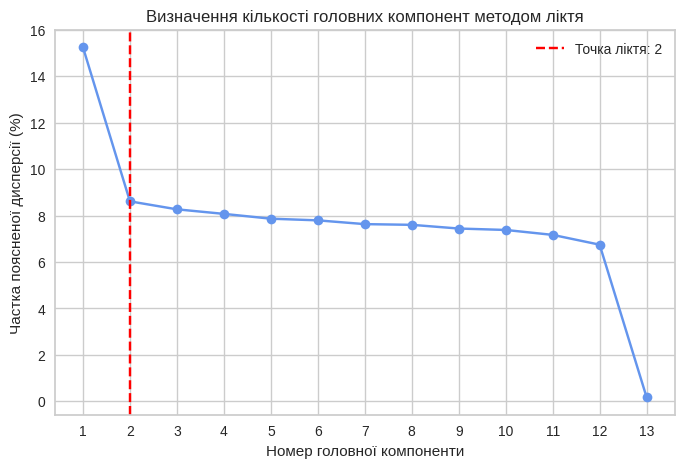

In [62]:
components = np.arange(1, len(explained_variance) + 1)

knee = KneeLocator(
    components,
    explained_variance,
    curve = 'convex',
    direction = 'decreasing'
)

n_components = knee.knee

print("Автоматично визначена кількість головних компонент:", n_components)

plt.figure(figsize = (8, 5))

plt.plot(
    components,
    explained_variance * 100,
    marker = 'o',
    color = 'cornflowerblue'
)

if n_components is not None:
    plt.axvline(
        x = n_components,
        color = 'red',
        linestyle = '--',
        label = f'Точка ліктя: {n_components}'
    )

plt.xlabel('Номер головної компоненти')
plt.ylabel('Частка поясненої дисперсії (%)')
plt.title('Визначення кількості головних компонент методом ліктя')
plt.xticks(components)
plt.legend() if n_components is not None else None
plt.grid(True)
plt.show()

###**Пояснення:**

Для автоматичного визначення доцільної кількості головних компонент набору даних `Students Performance Dataset` застосовано алгоритм `KneeLocator`, який дозволяє знаходити характерну точку вигину на графіку залежності частки поясненої дисперсії від номера головної компоненти.

За допомогою функції `np.arange()` сформовано масив `components`, який містить порядкові номери всіх 13 головних компонент. Для пошуку точки ліктя використано клас `KneeLocator` із параметрами `curve = 'convex'` та `direction = 'decreasing'`, які відповідають опуклій спадній формі кривої поясненої дисперсії.

Атрибут `knee.knee` дозволяє отримати номер головної компоненти, що відповідає автоматично визначеній точці ліктя. Отримане значення збережено у змінній `n_components`.

Для графічного представлення результатів за допомогою `plt.plot()` побудовано графік залежності частки поясненої дисперсії від номера головної компоненти. Додатково функцією `plt.axvline()` позначено знайдену точку ліктя червоною пунктирною вертикальною лінією.

Аналіз отриманого графіка показує, що найбільшу частку дисперсії пояснює перша головна компонента `PC1` – 15,25%. При переході до другої компоненти значення різко зменшується до 8,61%, тоді як для третьої компоненти становить 8,27%.

Починаючи з другої компоненти, спостерігається значно повільніше зменшення частки поясненої дисперсії. Значення для компонент `PC3–PC12` поступово знижуються приблизно від 8,27% до 6,75%, а остання компонента `PC13` пояснює лише 0,18% загальної дисперсії.

На графіку спостерігається характерний вигин після першої компоненти, внаслідок чого алгоритм `KneeLocator` автоматично визначив точку ліктя при `n_components = 2`.

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

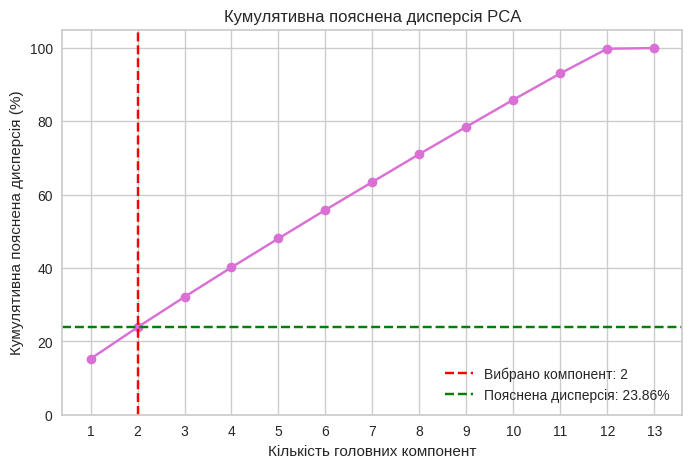


Вибрана кількість головних компонент: 2
Фактична частка поясненої дисперсії: 23.86%
Розмір матриці після PCA: (2392, 2)


In [63]:
cumulative_variance = np.cumsum(explained_variance)

if n_components is None:
    n_components = len(explained_variance)
    print("Точку ліктя не знайдено. Використовуються всі компоненти.")

selected_variance = cumulative_variance[n_components - 1]

plt.figure(figsize = (8, 5))

plt.plot(
    components,
    cumulative_variance * 100,
    marker = 'o',
    color = 'orchid'
)

plt.axvline(
    x = n_components,
    color = 'red',
    linestyle = '--',
    label = f'Вибрано компонент: {n_components}'
)

plt.axhline(
    y = selected_variance * 100,
    color = 'green',
    linestyle = '--',
    label = f'Пояснена дисперсія: {selected_variance * 100:.2f}%'
)

plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна пояснена дисперсія (%)')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xticks(components)
plt.ylim(0, 105)
plt.legend()
plt.grid(True)
plt.show()

pca_final = PCA(n_components = n_components, random_state = 42)
X_pca_final = pca_final.fit_transform(X_pca_scaled)

print(f"\nВибрана кількість головних компонент: {n_components}")
print(f"Фактична частка поясненої дисперсії: {selected_variance * 100:.2f}%")
print("Розмір матриці після PCA:", X_pca_final.shape)

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

###**Пояснення:**

Для визначення фактичної частки дисперсії, що відповідає автоматично вибраній кількості компонент, використано вираз `cumulative_variance[n_components - 1]`. Віднімання одиниці необхідне через те, що нумерація головних компонент починається з 1, тоді як індексація масивів Python – з 0.

За допомогою `plt.plot()` побудовано графік залежності кумулятивної поясненої дисперсії від кількості головних компонент. Для наочного представлення результатів використано дві допоміжні лінії:

- Червона вертикальна пунктирна лінія – позначає автоматично визначену кількість головних компонент (`n_components = 2`).

- Зелена горизонтальна пунктирна лінія – відображає фактичну частку поясненої дисперсії, яка зберігається після вибору двох компонент (23,86%).

Після побудови графіка створено модель `PCA(n_components = n_components, random_state = 42)`, яка виконує зменшення розмірності початкових стандартизованих даних. За допомогою методу `fit_transform(X_pca_scaled)` здійснено перетворення 13 початкових ознак у простір двох головних компонент. Отримані результати збережено в матриці `X_pca_final`.

Аналіз отриманого графіка кумулятивної поясненої дисперсії показує, що зі збільшенням кількості головних компонент поступово зростає частка загальної дисперсії, яка зберігається після перетворення `PCA`.

Перша головна компонента пояснює 15,25% загальної дисперсії, а перші дві компоненти разом – 23,86%. При збільшенні кількості компонент до трьох накопичена частка дисперсії становить 32,13%, а для чотирьох – 40,20%.

Подальше збільшення кількості компонент забезпечує поступове зростання кумулятивної дисперсії. При використанні восьми компонент зберігається приблизно 71,08% загальної дисперсії, десяти – близько 85,90%, а дванадцяти – приблизно 99,82%. Використання всіх 13 головних компонент дозволяє зберегти 100% початкової дисперсії.`

Отримані результати показують, що після застосування `PCA` розмірність набору даних зменшилася з 13 до 2 ознак, тоді як кількість записів залишилася незмінною – 2392 студенти.

Водночас дві вибрані головні компоненти пояснюють лише 23,86% загальної дисперсії, а решта 76,14% не зберігається у сформованому двовимірному представленні.

Це свідчить про суттєве зменшення обсягу інформації про мінливість початкових характеристик студентів. Хоча автоматично знайдена точка ліктя дозволяє обрати компактне двовимірне представлення даних, така кількість компонент не забезпечує збереження більшої частини загальної дисперсії.

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [64]:
from yellowbrick.cluster import KElbowVisualizer

print("Інструмент KElbowVisualizer успішно імпортовано.")

Інструмент KElbowVisualizer успішно імпортовано.


###**Пояснення:**

За допомогою оператора `from ... import` виконано імпорт класу `KElbowVisualizer` із модуля `yellowbrick.cluster`, який використовується для автоматизованого визначення оптимальної кількості кластерів за допомогою методу ліктя (`Elbow Method`).

Інструмент `KElbowVisualizer` дозволяє послідовно навчати моделі кластеризації з різною кількістю кластерів, обчислювати відповідні показники якості та будувати графік залежності внутрішньокластерної суми квадратів відстаней (`WCSS`) від кількості кластерів.

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

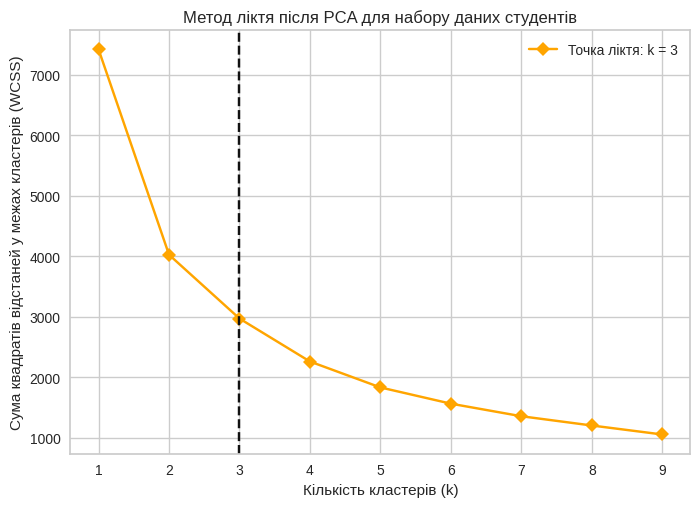

Оптимальна кількість кластерів після PCA: 3


In [65]:
kmeans_pca = KMeans(
    init = 'k-means++',
    max_iter = 300,
    random_state = 42,
    n_init = 10
)

visualizer = KElbowVisualizer(
    kmeans_pca,
    k = (1, 10),
    metric = 'distortion',
    timings = False,
    locate_elbow = True
)

visualizer.fit(X_pca_final)

visualizer.finalize()

visualizer.ax.lines[0].set_color('orange')
visualizer.ax.lines[0].set_markerfacecolor('orange')
visualizer.ax.lines[0].set_markeredgecolor('orange')

visualizer.ax.set_title('Метод ліктя після PCA для набору даних студентів')
visualizer.ax.set_xlabel('Кількість кластерів (k)')
visualizer.ax.set_ylabel('Сума квадратів відстаней у межах кластерів (WCSS)')

if visualizer.elbow_value_ is not None:
    visualizer.ax.legend(
        [f'Точка ліктя: k = {visualizer.elbow_value_}'],
        loc = 'upper right'
    )

visualizer.ax.grid(True)
plt.show()

print("Оптимальна кількість кластерів після PCA:", visualizer.elbow_value_)

###**Пояснення:**

Для визначення оптимальної кількості кластерів набору даних `Students Performance Dataset` після застосування методу головних компонент (`PCA`) використано алгоритм `K-Means` та інструмент `KElbowVisualizer`, який автоматизує побудову графіка методу ліктя й визначення характерної точки вигину кривої.

Для кластеризації використано матрицю `X_pca_final` розмірністю (2392, 2), отриману після перетворення 13 початкових ознак на дві головні компоненти. Вибрані компоненти зберігають 23,86% загальної дисперсії початкових стандартизованих даних.

Спочатку за допомогою `KMeans()` створено модель кластеризації з такими параметрами:

- `init = 'k-means++'` – спосіб вибору початкових центрів кластерів;

- `max_iter = 300` – максимальна кількість ітерацій алгоритму;

- `random_state = 42` – забезпечує відтворюваність результатів;

- `n_init = 10` – визначає кількість незалежних запусків алгоритму з різними початковими центрами кластерів.

Для автоматичного визначення оптимальної кількості кластерів створено об'єкт `KElbowVisualizer`, у якому задано діапазон `k = (1, 10)`, що забезпечує перевірку кількості кластерів від 1 до 9 включно. Параметр `metric = 'distortion'` визначає використання показника внутрішньокластерної суми квадратів відстаней, `timings = False` вимикає відображення часу навчання моделей, а `locate_elbow = True` активує автоматичний пошук точки ліктя.

Метод `visualizer.fit(X_pca_final)` виконує послідовне навчання моделей `K-Means` для різної кількості кластерів на даних після `PCA`.

Для зміни кольору графіка використано методи `set_color()`, `set_markerfacecolor()` та `set_markeredgecolor()`, які забезпечують відображення лінії та маркерів помаранчевим кольором. Атрибут `visualizer.elbow_value_` повертає автоматично визначену оптимальну кількість кластерів.

Аналіз отриманого графіка методу ліктя показує, що зі збільшенням кількості кластерів значення `WCSS` поступово зменшується. Найбільш суттєве зниження спостерігається під час переходу від одного до двох кластерів – приблизно з 7400 до 4000, що свідчить про значне покращення компактності сформованих груп.

При збільшенні кількості кластерів до трьох значення `WCSS` зменшується приблизно до 2968,11, а для чотирьох кластерів – до 2250. Подальше збільшення кількості кластерів супроводжується поступовим зниженням показника, проте темп цього зменшення стає менш вираженим.

Для п'яти кластерів значення `WCSS` становить приблизно 1850, для шести – 1580, а при збільшенні кількості кластерів до дев'яти зменшується приблизно до 1050.

На графіку спостерігається характерний вигин поблизу `k = 3`, після якого крива поступово вирівнюється. Алгоритм `KElbowVisualizer` автоматично визначив цю точку як оптимальну.

Порівняння з попередніми результатами кластеризації показує, що метод ліктя після `PCA` визначив оптимальну кількість кластерів `k = 3`, тоді як метод силуетів для чотирьох початкових ознак (`Age`, `StudyTimeWeekly`, `Absences`, `GPA`) показав найкращий результат при `k = 2` із середнім коефіцієнтом приблизно 0,308.

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

###**Підсумкові висновки:**

За результатами порівняння різних способів визначення оптимальної кількості кластерів встановлено, що метод ліктя та метод силуетів можуть давати різні результати, оскільки використовують різні критерії оцінювання.

Для набору даних `Iris` метод ліктя вказав на доцільність використання трьох кластерів, тоді як метод силуетів визначив оптимальними два кластери із середнім коефіцієнтом 0,582.

Для набору даних студентів метод ліктя за чотирма числовими ознаками не продемонстрував чітко вираженого вигину, а метод силуетів показав найкращий результат при двох кластерах із коефіцієнтом 0,308.

Після застосування `PCA` автоматизований метод ліктя визначив оптимальну кількість кластерів `k = 3`.

Отже, вибір кількості кластерів залежить від характеристик даних, використаного простору ознак та критерію оцінювання якості кластеризації.

Під час дослідження набору даних `Students Performance Dataset` встановлено, що класифікація та кластеризація відрізняються способом використання цільової змінної.

У задачі класифікації використовується відома цільова ознака `GradeClass`, яка визначає категорію академічної успішності студента.

На її основі моделі навчаються прогнозувати належність студентів до відповідних класів.

Натомість кластеризація виконується без використання `GradeClass` і передбачає самостійне формування груп студентів за подібністю їхніх характеристик.

Тому кількість сформованих кластерів та їхній склад не обов'язково збігаються з відомими категоріями академічної успішності.

За результатами застосування методу головних компонент (`PCA`) за допомогою алгоритму `KneeLocator` автоматично обрано 2 головні компоненти, які разом пояснюють 23,86% загальної дисперсії початкових стандартизованих даних. У результаті кількість ознак зменшено з 13 до 2.

Водночас збережена частка дисперсії є відносно низькою, що свідчить про втрату 76,14% початкової дисперсії.

Отже, використання двох головних компонент дозволяє спростити представлення даних і виконати двовимірну кластеризацію, проте результати необхідно інтерпретувати з урахуванням суттєвого скорочення інформації про мінливість початкових ознак.